# QR Pipeline — Chạy từng bước
Mỗi cell thực hiện đúng 1 bước, hiển thị ảnh bằng `matplotlib` để trực quan hoá.

### **Các luồng giải mã theo thứ tự ưu tiên:**
1. **Lần 1**: Ảnh sau Warp Perspective
2. **Fallback 1**: Ảnh Warp + **Upscale 2x + Otsu Threshold**
3. **Fallback 2**: Real-ESRGAN (SR) + **Upscale 2x + Otsu Threshold** *(không đọc ảnh SR thô)*
4. **Fallback 3 (Luồng cuối)**: Real-ESRGAN (SR) + **Upscale 2x + Adaptive Threshold (blockSize=101)**

In [1]:
import sys, os
_ROOT = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
if _ROOT not in sys.path:
    sys.path.insert(0, _ROOT)

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def show(img, title="", cmap=None):
    plt.figure(figsize=(6, 6))
    if cmap is None and img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# ── Cấu hình đường dẫn ───────────────────────────────────────────
IMAGE_PATH     = os.path.join(_ROOT, "adown.jpg")
SR_WEIGHT      = os.path.join(_ROOT, "weights", "RealESRGAN_x4plus.pth")
# Đặt True để ép chạy TẤT CẢ các bước trên mọi QR để quan sát ảnh
FORCE_RUN_ALL  = True
# ─────────────────────────────────────────────────────────────────
print("Config OK — FORCE_RUN_ALL:", FORCE_RUN_ALL)

Config OK — FORCE_RUN_ALL: True


## Bước 0 — Đọc ảnh gốc

Kích thước ảnh: (1280, 720, 3)


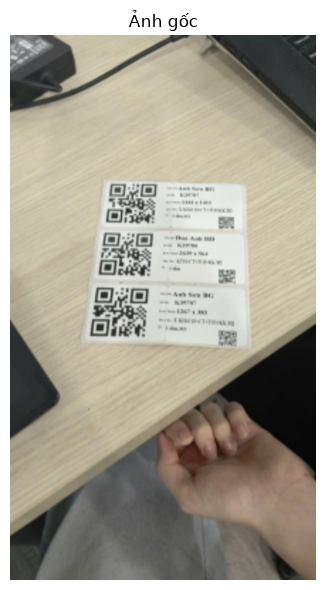

In [2]:
image_bgr = cv2.imread(IMAGE_PATH)
if image_bgr is None:
    raise FileNotFoundError(f"Không đọc được: {IMAGE_PATH}")

print(f"Kích thước ảnh: {image_bgr.shape}")
show(image_bgr, "Ảnh gốc")

## Bước 1 — Phát hiện QR (qrdet / YOLOv8)

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Số QR phát hiện: 3


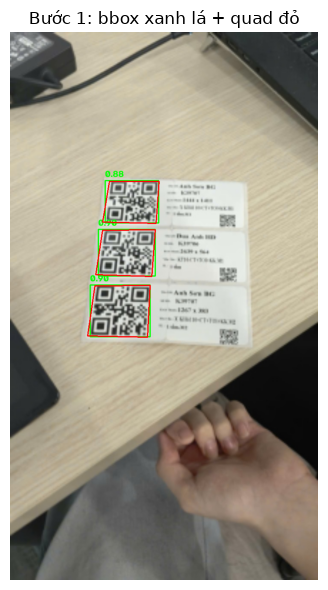

In [3]:
from production.detector import QRDetector

detector = QRDetector(model_size="s", conf_th=0.5)
detections = detector.detect(image_bgr)
print(f"Số QR phát hiện: {len(detections)}")

vis = image_bgr.copy()
for det in detections:
    x1, y1, x2, y2 = map(int, det.bbox_xyxy)
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
    pts = det.quad_xy.astype(np.int32).reshape((-1, 1, 2))
    cv2.polylines(vis, [pts], isClosed=True, color=(0, 0, 255), thickness=2)
    cv2.putText(vis, f"{det.confidence:.2f}", (x1, max(y1 - 8, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

show(vis, "Bước 1: bbox xanh lá + quad đỏ")

## Bước 2 — Crop + Warp Perspective

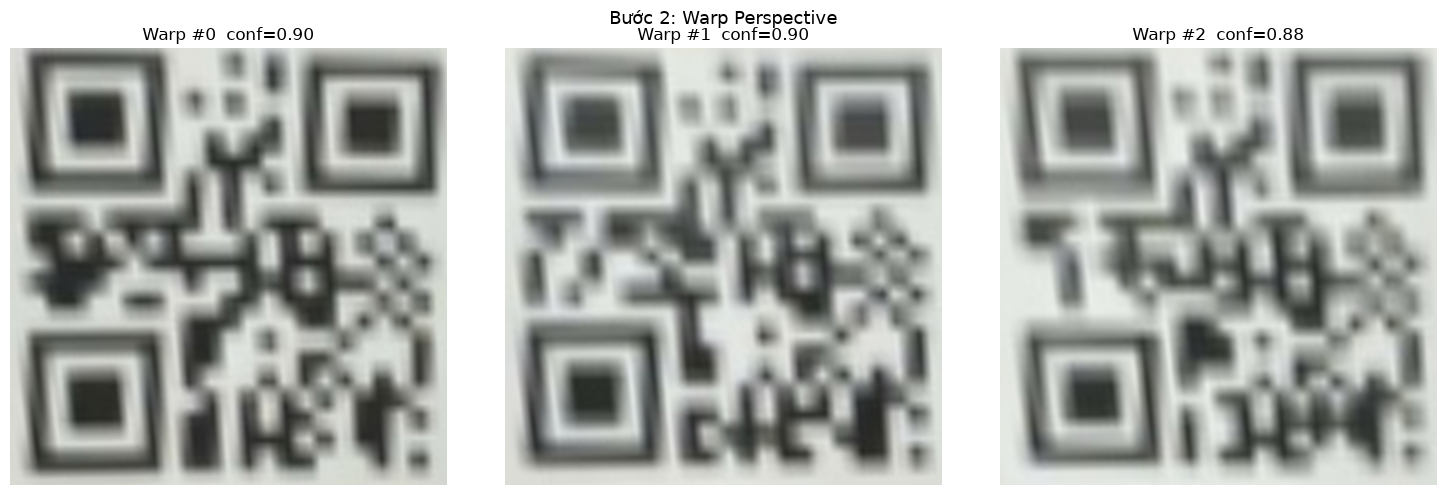

In [4]:
from production.corrector import warp_qr

if not detections:
    print("Không có detection để warp.")
    warped_list = []
else:
    warped_list = [warp_qr(image_bgr, det, out_size=512) for det in detections]

    cols = min(len(warped_list), 3)
    rows = (len(warped_list) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = np.array(axes).flatten() if len(warped_list) > 1 else [axes]
    for i, w in enumerate(warped_list):
        axes[i].imshow(cv2.cvtColor(w, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Warp #{i}  conf={detections[i].confidence:.2f}")
        axes[i].axis("off")
    for ax in axes[len(warped_list):]:
        ax.set_visible(False)
    plt.suptitle("Bước 2: Warp Perspective", fontsize=13)
    plt.tight_layout()
    plt.show()

## Bước 3 — Multi-Decoder lần 1 (ảnh Warp)

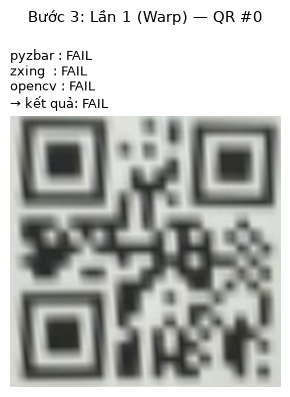

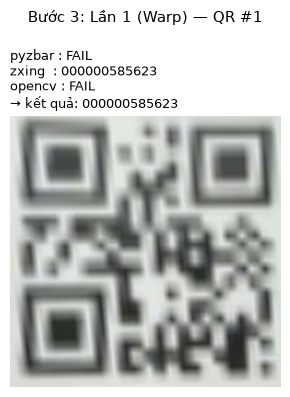

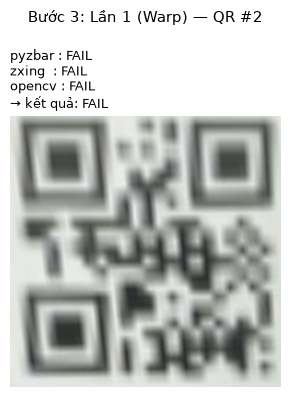

Lần 1 thành công: 1/3
QR sẽ chạy tiếp Fallback 1: [0, 1, 2]


In [5]:
from production.decoder import _decode_pyzbar, _decode_zxing, _decode_opencv

decode1_results = []
for i, w in enumerate(warped_list):
    r_pyzbar = _decode_pyzbar(w)
    r_zxing  = _decode_zxing(w)
    r_opencv = _decode_opencv(w)
    result   = r_pyzbar or r_zxing or r_opencv
    decode1_results.append(result)

    label = (
        f"pyzbar : {r_pyzbar or 'FAIL'}\n"
        f"zxing  : {r_zxing  or 'FAIL'}\n"
        f"opencv : {r_opencv or 'FAIL'}\n"
        f"→ kết quả: {result or 'FAIL'}"
    )
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(cv2.cvtColor(w, cv2.COLOR_BGR2RGB))
    ax.set_title(label, fontsize=9, loc="left")
    ax.axis("off")
    plt.suptitle(f"Bước 3: Lần 1 (Warp) — QR #{i}", fontsize=11)
    plt.tight_layout()
    plt.show()

failed_idx_1 = [i for i, r in enumerate(decode1_results) if not r]
targets_otsu1 = list(range(len(warped_list))) if FORCE_RUN_ALL else failed_idx_1
print(f"Lần 1 thành công: {sum(bool(r) for r in decode1_results)}/{len(decode1_results)}")
print(f"QR sẽ chạy tiếp Fallback 1: {targets_otsu1}")

## Fallback 1 — Warp + Upscale 2x + Otsu Threshold

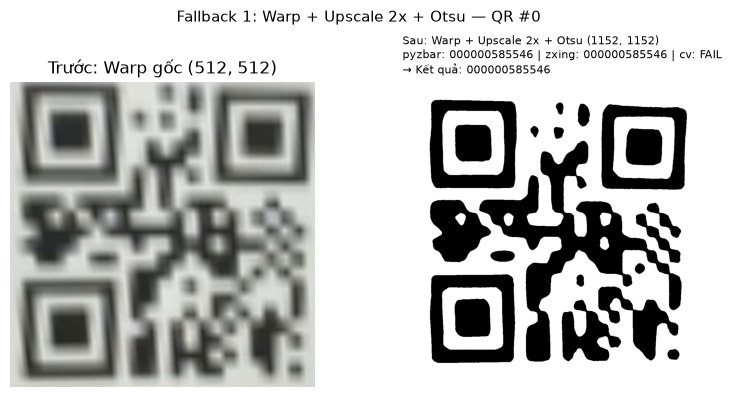

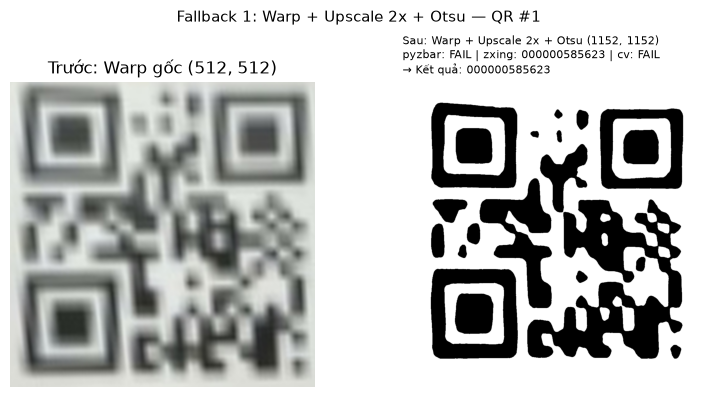

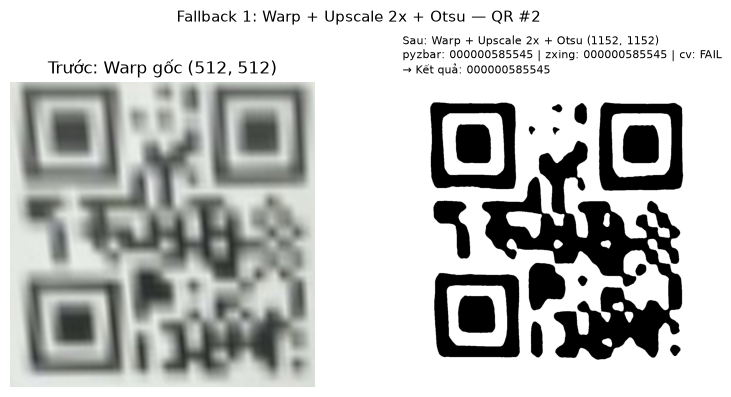

Fallback 1 thành công: 3/3
QR sẽ cần fallback sang Real-ESRGAN: [0, 1, 2]


In [6]:
from production.preprocessor import upscale_otsu

warp_otsu_images = {}
decode_warp_otsu_results = {}

for i in targets_otsu1:
    otsu_img = upscale_otsu(warped_list[i], scale=2.0)
    warp_otsu_images[i] = otsu_img

    r_pyzbar = _decode_pyzbar(otsu_img)
    r_zxing  = _decode_zxing(otsu_img)
    r_opencv = _decode_opencv(otsu_img)
    result   = r_pyzbar or r_zxing or r_opencv
    decode_warp_otsu_results[i] = result

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(cv2.cvtColor(warped_list[i], cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Trước: Warp gốc {warped_list[i].shape[:2]}")
    axes[0].axis("off")
    
    axes[1].imshow(cv2.cvtColor(otsu_img, cv2.COLOR_BGR2RGB))
    label = (
        f"Sau: Warp + Upscale 2x + Otsu {otsu_img.shape[:2]}\n"
        f"pyzbar: {r_pyzbar or 'FAIL'} | zxing: {r_zxing or 'FAIL'} | cv: {r_opencv or 'FAIL'}\n"
        f"→ Kết quả: {result or 'FAIL'}"
    )
    axes[1].set_title(label, fontsize=8, loc="left")
    axes[1].axis("off")
    
    plt.suptitle(f"Fallback 1: Warp + Upscale 2x + Otsu — QR #{i}", fontsize=11)
    plt.tight_layout()
    plt.show()

failed_after_otsu1 = [
    i for i in range(len(warped_list))
    if not (decode1_results[i] or decode_warp_otsu_results.get(i))
]
targets_sr = list(range(len(warped_list))) if FORCE_RUN_ALL else failed_after_otsu1
print(f"Fallback 1 thành công: {sum(bool(r) for r in decode_warp_otsu_results.values())}/{len(targets_otsu1)}")
print(f"QR sẽ cần fallback sang Real-ESRGAN: {targets_sr}")

## Bước 4 — Super-Resolution (Real-ESRGAN)

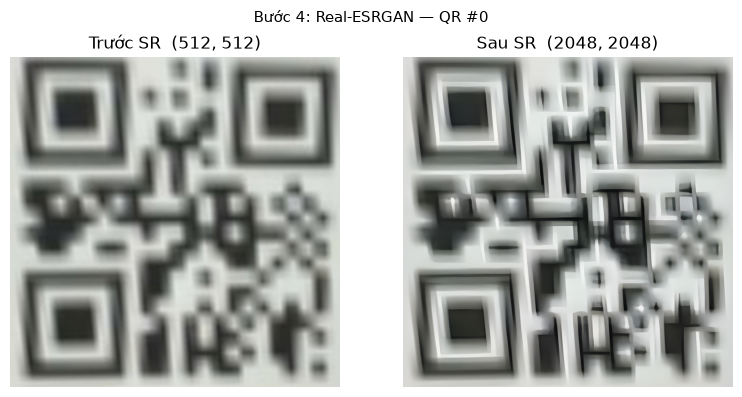

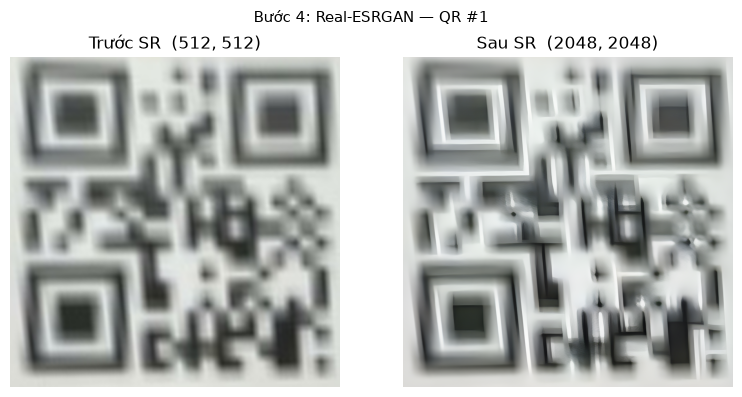

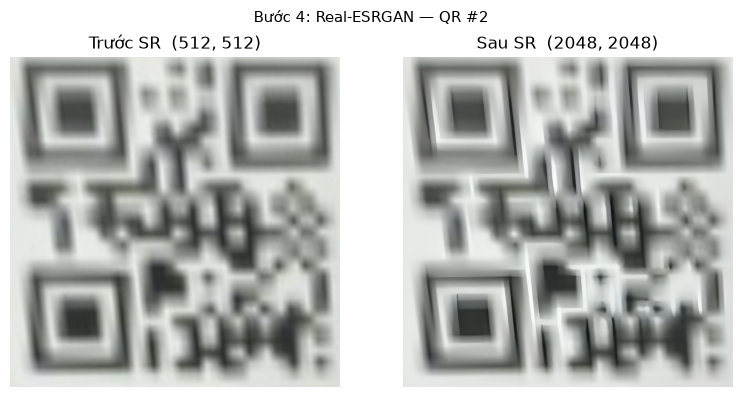

In [7]:
from production.super_resolution import SuperResolver

sr_images = {}
if not targets_sr:
    print("Không có QR nào cần SR.")
else:
    sr = SuperResolver(weight_path=SR_WEIGHT)
    for i in targets_sr:
        sr_img = sr.upscale(warped_list[i])
        sr_images[i] = sr_img

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        axes[0].imshow(cv2.cvtColor(warped_list[i], cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"Trước SR  {warped_list[i].shape[:2]}")
        axes[0].axis("off")
        axes[1].imshow(cv2.cvtColor(sr_img, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f"Sau SR  {sr_img.shape[:2]}")
        axes[1].axis("off")
        plt.suptitle(f"Bước 4: Real-ESRGAN — QR #{i}", fontsize=11)
        plt.tight_layout()
        plt.show()

## Fallback 2 — Real-ESRGAN + Upscale 2x + Otsu Threshold

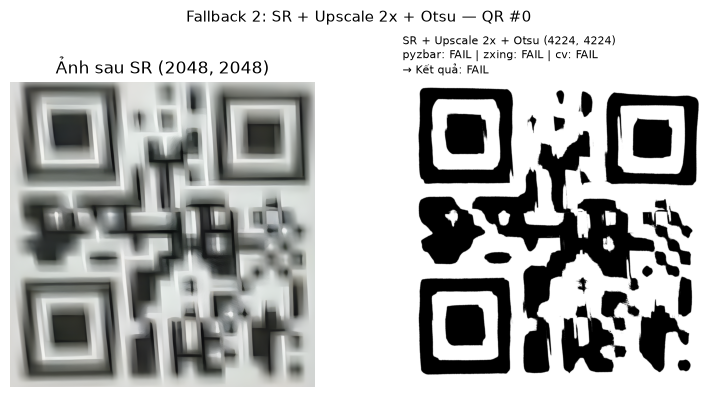

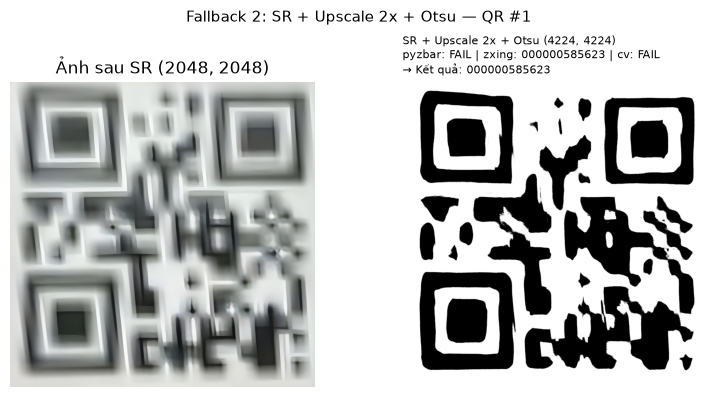

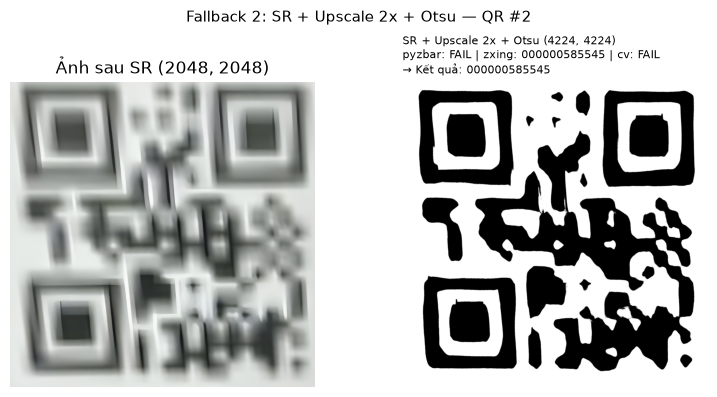

In [8]:
sr_otsu_images = {}
decode_sr_otsu_results = {}

for i in targets_sr:
    img_sr = sr_images[i]
    sr_otsu = upscale_otsu(img_sr, scale=2.0)
    sr_otsu_images[i] = sr_otsu

    r_pyzbar = _decode_pyzbar(sr_otsu)
    r_zxing  = _decode_zxing(sr_otsu)
    r_opencv = _decode_opencv(sr_otsu)
    result   = r_pyzbar or r_zxing or r_opencv
    decode_sr_otsu_results[i] = result

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(cv2.cvtColor(img_sr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Ảnh sau SR {img_sr.shape[:2]}")
    axes[0].axis("off")
    
    axes[1].imshow(cv2.cvtColor(sr_otsu, cv2.COLOR_BGR2RGB))
    label = (
        f"SR + Upscale 2x + Otsu {sr_otsu.shape[:2]}\n"
        f"pyzbar: {r_pyzbar or 'FAIL'} | zxing: {r_zxing or 'FAIL'} | cv: {r_opencv or 'FAIL'}\n"
        f"→ Kết quả: {result or 'FAIL'}"
    )
    axes[1].set_title(label, fontsize=8, loc="left")
    axes[1].axis("off")
    
    plt.suptitle(f"Fallback 2: SR + Upscale 2x + Otsu — QR #{i}", fontsize=11)
    plt.tight_layout()
    plt.show()

## Fallback 3 (Luồng cuối) — Real-ESRGAN + Upscale 2x + Adaptive Threshold (blockSize=101)

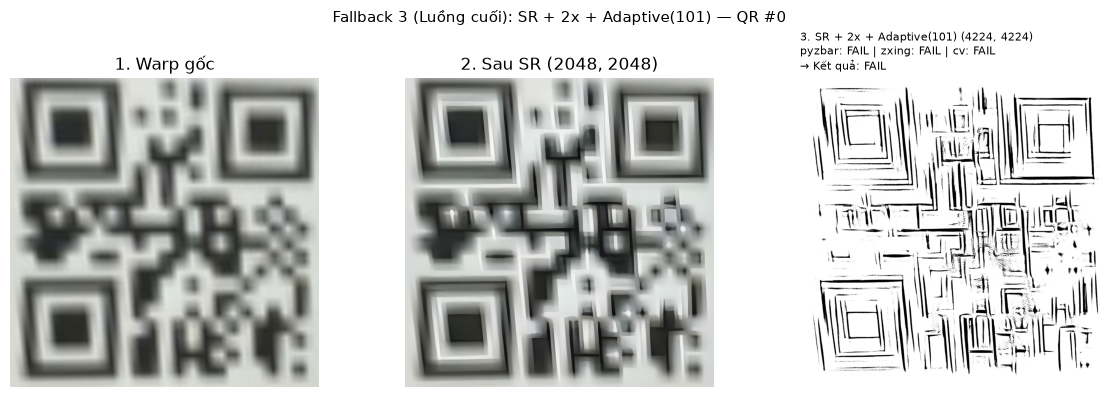

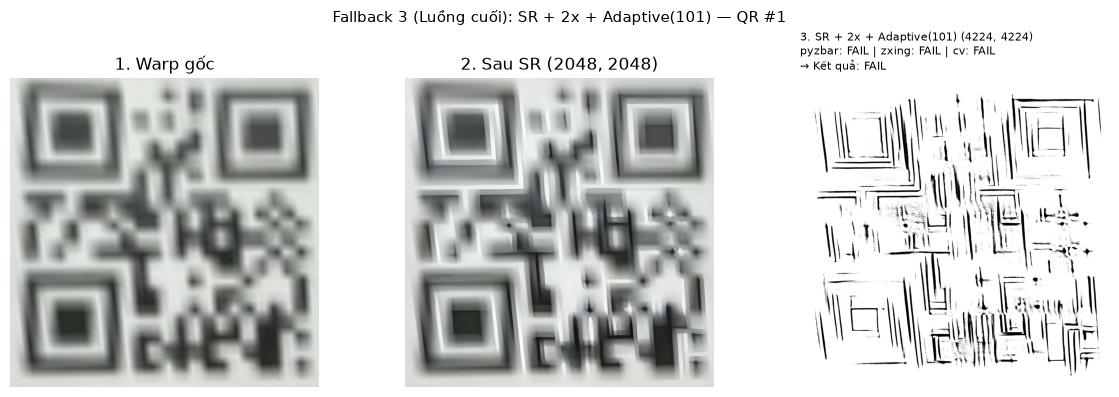

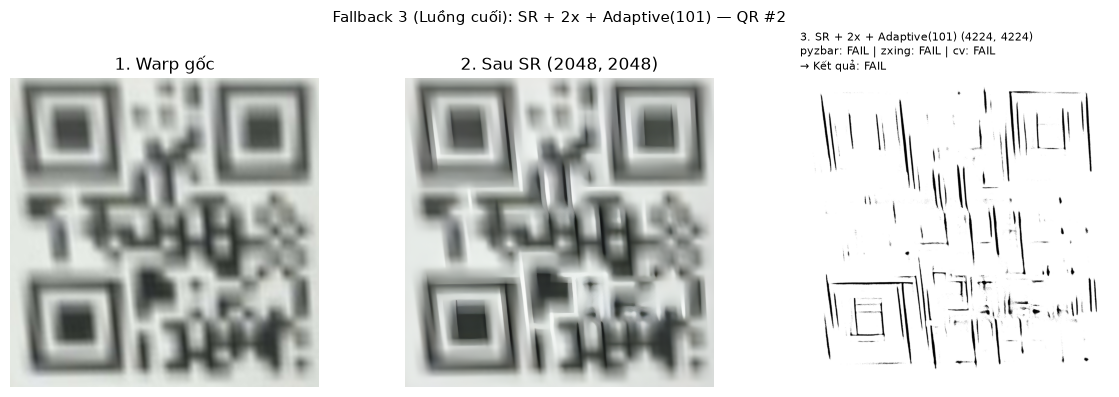

In [9]:
from production.preprocessor import upscale_adaptive

sr_adaptive_images = {}
decode_sr_adaptive_results = {}

for i in targets_sr:
    img_sr = sr_images[i]
    sr_ad = upscale_adaptive(img_sr, scale=2.0, block_size=101)
    sr_adaptive_images[i] = sr_ad

    r_pyzbar = _decode_pyzbar(sr_ad)
    r_zxing  = _decode_zxing(sr_ad)
    r_opencv = _decode_opencv(sr_ad)
    result   = r_pyzbar or r_zxing or r_opencv
    decode_sr_adaptive_results[i] = result

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(warped_list[i], cv2.COLOR_BGR2RGB))
    axes[0].set_title("1. Warp gốc")
    axes[0].axis("off")
    
    axes[1].imshow(cv2.cvtColor(img_sr, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"2. Sau SR {img_sr.shape[:2]}")
    axes[1].axis("off")
    
    axes[2].imshow(cv2.cvtColor(sr_ad, cv2.COLOR_BGR2RGB))
    label = (
        f"3. SR + 2x + Adaptive(101) {sr_ad.shape[:2]}\n"
        f"pyzbar: {r_pyzbar or 'FAIL'} | zxing: {r_zxing or 'FAIL'} | cv: {r_opencv or 'FAIL'}\n"
        f"→ Kết quả: {result or 'FAIL'}"
    )
    axes[2].set_title(label, fontsize=8, loc="left")
    axes[2].axis("off")
    
    plt.suptitle(f"Fallback 3 (Luồng cuối): SR + 2x + Adaptive(101) — QR #{i}", fontsize=11)
    plt.tight_layout()
    plt.show()

## So sánh kết quả qua tất cả các luồng & Kết luận

QR    1. Warp            2. Warp+Otsu       3. SR+Otsu             4. SR+Adaptive(101)   
#0    FAIL               000000585546       -                      -                     
#1    000000585623       000000585623       000000585623           -                     
#2    FAIL               000000585545       000000585545           -                     


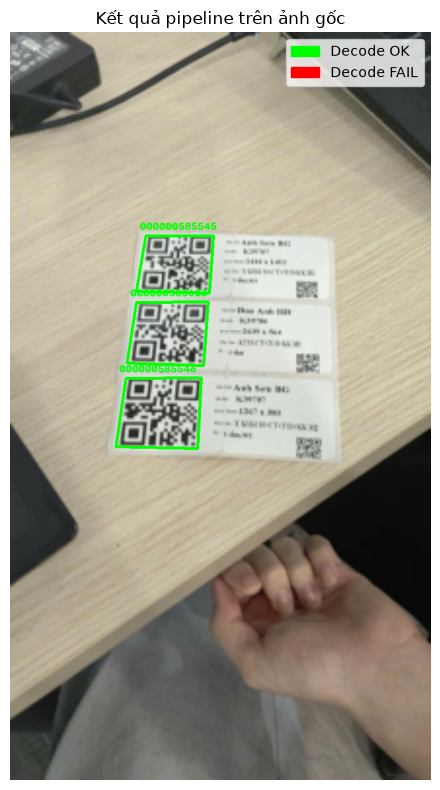

In [10]:
print("=" * 95)
print(f"{'QR':<5} {'1. Warp':<18} {'2. Warp+Otsu':<18} {'3. SR+Otsu':<22} {'4. SR+Adaptive(101)':<22}")
print("=" * 95)
for i in range(len(warped_list)):
    r1   = (decode1_results[i]               or "FAIL")[:16]
    r_w_ot = (decode_warp_otsu_results.get(i) or "-")[:16]
    r_sr_ot = (decode_sr_otsu_results.get(i)  or "-")[:20]
    r_sr_ad = (decode_sr_adaptive_results.get(i) or "-")[:20]
    print(f"#{i:<4} {r1:<18} {r_w_ot:<18} {r_sr_ot:<22} {r_sr_ad:<22}")
print("=" * 95)

# Quyết định kết quả cuối cùng theo đúng thứ tự ưu tiên của Pipeline:
# Lần 1 -> Fallback 1 (Warp+Otsu) -> Fallback 2 (SR+Otsu) -> Fallback 3 (SR+Adaptive)
final = {}
for i in range(len(warped_list)):
    final[i] = (
        decode1_results[i]
        or decode_warp_otsu_results.get(i)
        or decode_sr_otsu_results.get(i)
        or decode_sr_adaptive_results.get(i)
    )

# Vẽ kết quả lên ảnh gốc
vis_final = image_bgr.copy()
for i, det in enumerate(detections):
    pts = det.quad_xy.astype(np.int32).reshape((-1, 1, 2))
    color = (0, 255, 0) if final.get(i) else (0, 0, 255)
    cv2.polylines(vis_final, [pts], isClosed=True, color=color, thickness=3)
    x1, y1 = int(det.bbox_xyxy[0]), int(det.bbox_xyxy[1])
    label = (final.get(i) or "FAIL")[:25]
    cv2.putText(vis_final, label, (x1, max(y1 - 8, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

ok_patch   = mpatches.Patch(color="lime", label="Decode OK")
fail_patch = mpatches.Patch(color="red",  label="Decode FAIL")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(vis_final, cv2.COLOR_BGR2RGB))
plt.title("Kết quả pipeline trên ảnh gốc")
plt.legend(handles=[ok_patch, fail_patch], loc="upper right")
plt.axis("off")
plt.tight_layout()
plt.show()